# Assignment 2: Linear Models and Support Vector Machines

.

In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_digits, load_iris
from sklearn.model_selection import train_test_split

SEED = 42
np.set_printoptions(precision=4, suppress=True)

## Task 1: Load the datasets



In [102]:
diab = load_diabetes(scaled=False)
X_diab, y_diab = diab.data, diab.target


bc = load_breast_cancer()
X_bc, y_bc = bc.data, 1 - bc.target

dig = load_digits()
X_dig, y_dig = dig.data / 16, dig.target

iris = load_iris()
X_iris, y_iris = iris.data, iris.target

print("Diabetes      X:", X_diab.shape, " y:", y_diab.shape)
print("Breast cancer X:", X_bc.shape, " y:", y_bc.shape)
print("Digits        X:", X_dig.shape, " y:", y_dig.shape)
print("Iris          X:", X_iris.shape, " y:", y_iris.shape)
print("Malignant count  :", y_bc.sum())

Diabetes      X: (442, 10)  y: (442,)
Breast cancer X: (569, 30)  y: (569,)
Digits        X: (1797, 64)  y: (1797,)
Iris          X: (150, 4)  y: (150,)
Malignant count  : 212


## PART1.A: Train / validation / test split

In [103]:

def split_data(X, y, stratify=True):

    if stratify:
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.2, random_state=42, stratify=y)

        X_tr, X_va, y_tr, y_va = train_test_split(
            X_tr, y_tr, test_size=0.25, random_state=42, stratify=y_tr)

    else:
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.2, random_state=42)

        X_tr, X_va, y_tr, y_va = train_test_split(
            X_tr, y_tr, test_size=0.25, random_state=42)

    return X_tr, X_va, X_te, y_tr, y_va, y_te


X_tr_diab, X_va_diab, X_te_diab, y_tr_diab, y_va_diab, y_te_diab = split_data(X_diab, y_diab, stratify=False)
X_tr_bc, X_va_bc, X_te_bc, y_tr_bc, y_va_bc, y_te_bc = split_data(X_bc, y_bc)
X_tr_dig, X_va_dig, X_te_dig, y_tr_dig, y_va_dig, y_te_dig = split_data(X_dig, y_dig)
X_tr_iris, X_va_iris, X_te_iris, y_tr_iris, y_va_iris, y_te_iris = split_data(X_iris, y_iris)


splits = [
    ("Diabetes", y_tr_diab, y_va_diab, y_te_diab),
    ("Breast cancer", y_tr_bc, y_va_bc, y_te_bc),
    ("Digits", y_tr_dig, y_va_dig, y_te_dig),
    ("Iris", y_tr_iris, y_va_iris, y_te_iris),
]

for name, y_tr, y_va, y_te in splits:
    print(f"{name:14s} train={len(y_tr):5d}  val={len(y_va):4d}  test={len(y_te):4d}  total={len(y_tr)+len(y_va)+len(y_te)}")
    if name != "Diabetes":
        print("   class counts train:", np.bincount(y_tr))
        print("   class counts val  :", np.bincount(y_va))
        print("   class counts test :", np.bincount(y_te))


Diabetes       train=  264  val=  89  test=  89  total=442
Breast cancer  train=  341  val= 114  test= 114  total=569
   class counts train: [214 127]
   class counts val  : [71 43]
   class counts test : [72 42]
Digits         train= 1077  val= 360  test= 360  total=1797
   class counts train: [106 109 107 109 109 109 109 107 104 108]
   class counts val  : [36 37 35 37 36 36 36 36 35 36]
   class counts test : [36 36 35 37 36 37 36 36 35 36]
Iris           train=   90  val=  30  test=  30  total=150
   class counts train: [30 30 30]
   class counts val  : [10 10 10]
   class counts test : [10 10 10]


## PARTA.2: Standardizer and add_bias

**Standardizer.** Each feature column is transformed as z = (x − μ) / σ. μ and σ are computed in `fit` from the training rows only, then `transform` applies those same values to any set (train, validation or test). If a column is constant (σ = 0), σ is replaced by 1 so we never divide by zero.

**add_bias.** Adds a column of ones at the left of X, giving X̃ = [1 | X]. The bias w₀ is then just another weight, and the score is simply ŷ = X̃w.


In [104]:
class Standardizer:
    """
    Standardizes features: z = (x - mu) / sigma.
    mu and sigma come from the TRAINING rows only (call fit on training data).
    """
    def fit(self, X):
        self.mu = X.mean(axis=0)
        self.sigma = X.std(axis=0)
        self.sigma[self.sigma == 0] = 1     # constant column: use sigma = 1 to avoid dividing by 0
        return self

    def transform(self, X):
        return (X - self.mu) / self.sigma

    
def add_bias(X):
    """
    Args:
      X (ndarray (m,n)) : features
    Returns:
      (ndarray (m,n+1)) : [1 | X], a column of ones added on the left
    """
    return np.hstack([np.ones((X.shape[0], 1)), X])

## Verify the Standardizer on diabetes dataset

The Standardizer is fitted on the **training** rows of Diabetes only, then applied unchanged to validation and test.

**Check:** the standardized training columns must have |mean| < 1e-9(close to 0) and std = 1, while the validation and test columns should generally not.

In [105]:
sc_diab = Standardizer().fit(X_tr_diab) 
Z_tr = sc_diab.transform(X_tr_diab)
Z_va = sc_diab.transform(X_va_diab)
Z_te = sc_diab.transform(X_te_diab)

print("train max |mean| :", np.abs(Z_tr.mean(axis=0)).max())
print("train std        :", Z_tr.std(axis=0))
print("val   mean       :", Z_va.mean(axis=0))
print("val   std        :", Z_va.std(axis=0))
print("test  mean       :", Z_te.mean(axis=0))
print("test  std        :", Z_te.std(axis=0))

assert np.abs(Z_tr.mean(axis=0)).max() < 1e-9
assert np.allclose(Z_tr.std(axis=0), 1)

train max |mean| : 2.2372676102294822e-15
train std        : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
val   mean       : [ 0.0231 -0.1458  0.043   0.1933  0.1431  0.0401  0.2174 -0.029   0.0104
 -0.2211]
val   std        : [0.9974 0.9859 1.0047 1.0004 0.9291 0.8845 1.1316 1.0666 1.1677 1.0717]
test  mean       : [-0.1488 -0.0559 -0.172  -0.0727  0.093   0.0919  0.1635 -0.0472 -0.1295
 -0.2546]
test  std        : [1.1232 0.9972 1.0255 0.908  0.9675 0.9697 1.0979 0.9999 1.0166 0.925 ]


We calculate μ (mean) and σ (standard deviation) using training rows only because the model should learn preprocessing from the training data, without seeing validation or test data.
If we calculate them using all rows, information from the test set leaks into the training process. This is called data leakage.We use training statistics only to ensure the test set remains unseen until the final evaluation, giving us a fair estimate of how well the model performs on new dat

## PARTA.3: Evaluation metrics

In [106]:
def mse(y, y_pred):
    """Mean squared error: mean((y - y_pred)^2)."""
    return np.mean((y - y_pred) ** 2)

def rmse(y, y_pred):
    """Root mean squared error, in the same units as y."""
    return np.sqrt(mse(y, y_pred))

def r2(y, y_pred):
    """R^2 = 1 - SS_res / SS_tot."""
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return 1 - ss_res / ss_tot

def accuracy(y, pred):
    """Fraction of predictions that equal the true labels."""
    return np.mean(y == pred)

def confusion_matrix(y, pred, K):
    cm = np.zeros((K, K), dtype=int)
    np.add.at(cm, (y, pred), 1)
    return cm

def precision_recall_f1(cm):
    K = cm.shape[0]
    precision = []
    recall = []
    f1 = []

    for i in range(K):
        tp = cm[i, i]
        predicted = cm[:, i].sum()
        actual = cm[i, :].sum()

        p = tp / predicted if predicted > 0 else 0
        r = tp / actual if actual > 0 else 0
        f = 2 * p * r / (p + r) if p + r > 0 else 0

        precision.append(p)
        recall.append(r)
        f1.append(f)

    macro_precision = np.mean(precision)
    macro_recall = np.mean(recall)
    macro_f1 = np.mean(f1)

    return (np.array(precision), np.array(recall), np.array(f1),
            macro_precision, macro_recall, macro_f1)

### Check against scikit-learn
Random labels (K = 4, N = 500) are used for the classification metrics and random continuous values for the regression metrics. Every result must agree with `sklearn.metrics` to within 1e-12.

In [107]:
from sklearn import metrics as skm

rng = np.random.default_rng(SEED)
K = 4
y_true = rng.integers(0, K, size=500)
y_pred = rng.integers(0, K, size=500)

cm = confusion_matrix(y_true, y_pred, K)
p, r, f1, macro_p, macro_r, macro_f1 = precision_recall_f1(cm)


# Classification checks
assert np.array_equal(cm, skm.confusion_matrix(y_true, y_pred, labels=range(K)))
assert abs(accuracy(y_true, y_pred) - skm.accuracy_score(y_true, y_pred)) < 1e-12

# per class metrics
assert np.allclose(p, skm.precision_score(y_true, y_pred, average=None, zero_division=0), rtol=0, atol=1e-12)
assert np.allclose(r, skm.recall_score(y_true, y_pred, average=None, zero_division=0), rtol=0, atol=1e-12)
assert np.allclose(f1, skm.f1_score(y_true, y_pred, average=None, zero_division=0), rtol=0, atol=1e-12)

#per macro check
assert abs(macro_p - skm.precision_score(y_true, y_pred, average="macro", zero_division=0)) < 1e-12
assert abs(macro_r - skm.recall_score(y_true, y_pred, average="macro", zero_division=0)) < 1e-12
assert abs(macro_f1 - skm.f1_score(y_true, y_pred, average="macro", zero_division=0)) < 1e-12

# Regression checks
y_reg = rng.normal(size=500)
y_hat = y_reg + rng.normal(scale=0.5, size=500)

assert abs(mse(y_reg, y_hat) - skm.mean_squared_error(y_reg, y_hat)) < 1e-12
assert abs(rmse(y_reg, y_hat) - np.sqrt(skm.mean_squared_error(y_reg, y_hat))) < 1e-12
assert abs(r2(y_reg, y_hat) - skm.r2_score(y_reg, y_hat)) < 1e-12

print("All Task 3 checks passed")

All Task 3 checks passed


### Interpretation

All Task 3 evaluation metrics passed the verification checks against `sklearn.metrics` with a tolerance of \(10^{-12}\). This confirms that our implementations of the regression and classification metrics are correct. The confusion matrix also matches sklearn exactly.

## Task 4: Gradient checker

`grad_check(f, grad, w)` compares the analytic gradient with a numerical one computed by **central differences**:

(J(w + ε·eᵢ) − J(w − ε·eᵢ)) / (2ε)  for each parameter i.

- `f(w)` returns the scalar loss, and `grad(w)` returns the analytic gradient with the same shape as `w`.
- ε = 1e-5 by default (1e-6 for hinge losses).
- If `w` has more than 100 entries (softmax, multiclass SVM), 100 randomly chosen entries are checked.
- The function returns the relative error ‖g_analytic − g_numeric‖ / max(‖g_analytic‖, ‖g_numeric‖, 1e-12), which must be below 1e-6 (1e-5 for hinge losses).

**Check:** we test it on the linear-regression loss with the tiny dataset of Section 3.2. At w = 0 the gradient must be (−3.333, −7.667), and one gradient-descent step with η = 0.1 must give w = (0.333, 0.767).

In [108]:
def grad_check(f, grad, w, eps=1e-5, n_check=100):
    rng = np.random.default_rng(SEED)

    indices = np.arange(w.size)
    if w.size > n_check:
        indices = rng.choice(w.size, n_check, replace=False)

    numerical = np.zeros(len(indices))
    analytical = grad(w).ravel()[indices]

    for k, i in enumerate(indices):
        w_plus = w.copy()
        w_minus = w.copy()

        w_plus.flat[i] += eps
        w_minus.flat[i] -= eps

        numerical[k] = (f(w_plus) - f(w_minus)) / (2 * eps)

    return np.linalg.norm(analytical - numerical) / max(
        np.linalg.norm(analytical),
        np.linalg.norm(numerical),
        1e-12
    )

In [109]:
X = add_bias(np.array([[1.0], [2.0], [3.0]]))
y = np.array([2.0, 3.0, 5.0])
N = len(y)

def J(w):
    return np.sum((np.dot(X, w) - y) ** 2) / (2 * N)

def grad(w):
    return np.dot(X.T, (np.dot(X, w) - y)) / N


# Worked example from Section 3.2
w0 = np.zeros(2)
print("gradient at w=0   :", grad(w0))
print("one GD step (0.1) :", w0 - 0.1 * grad(w0))


# Gradient check at a random point w ~ N(0, 0.1^2)
rng = np.random.default_rng(SEED)
w_rand = rng.normal(0, 0.1, size=2)

err = grad_check(J, grad, w_rand)

print("relative error    :", err)
assert err < 1e-6

gradient at w=0   : [-3.3333 -7.6667]
one GD step (0.1) : [0.3333 0.7667]
relative error    : 1.2891976616317198e-11


**Interpretation.** At w = 0 the analytic gradient is (−3.333, −7.667) and one step with η = 0.1 gives w = (0.333, 0.767), both matching the worked example of Section 3.2. The relative error between the analytic and numerical gradient is far below 1e-6, so both the gradient formula and the `grad_check` function are correct. We will call `grad_check` in every later Part before trusting any gradient.

## Part B: Linear regression

Dataset: **Diabetes** (442 patients, 10 features, target = disease progression in its original units).

In [110]:
import time
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor   # reference checks only (Section 8)

feature_names = list(diab.feature_names)

scaler = Standardizer().fit(X_tr_diab)
X_train = add_bias(scaler.transform(X_tr_diab))
X_val   = add_bias(scaler.transform(X_va_diab))
X_test  = add_bias(scaler.transform(X_te_diab))

y_train, y_val, y_test = y_tr_diab, y_va_diab, y_te_diab
X_train_raw = add_bias(X_tr_diab)       # raw features, used in Task 7

N_train = len(y_train)

## Task 5: Closed form (normal equations)

**Derivation.** Start from J(w) = (1/2N)(X̃w − y)ᵀ(X̃w − y).

1. Differentiate: ∇J = (1/N) X̃ᵀ(X̃w − y).
2. At the minimum the gradient is zero: X̃ᵀ(X̃w − y) = 0.
3. Expand: X̃ᵀX̃ w − X̃ᵀy = 0.
4. Rearrange: **X̃ᵀX̃ w = X̃ᵀy** (the normal equations).

J is convex (its Hessian X̃ᵀX̃/N is positive semi-definite), so the point where ∇J = 0 is the global minimum. We solve the linear system directly with `np.linalg.solve` instead of computing the inverse (X̃ᵀX̃)⁻¹, which is faster and numerically more stable.

**Check:** on the worked example of Section 3.2 we expect X̃ᵀX̃ = [[3,6],[6,14]], X̃ᵀy = [10, 23] and w = (1/3, 3/2).

In [111]:

def normal_equation(X, y):
    w = np.linalg.solve(np.dot(X.T, X), np.dot(X.T, y))
    return w

### Diabetes: weights and errors

The closed-form solution w* is computed on the standardized training data (with the bias column). The table lists the weights; RMSE is in the original units of the target, and R² is measured on the test set.

**Verification:** `LinearRegression` from scikit-learn is fitted on the same standardized training data; its intercept and coefficients must match our weights to within 1e-6.

In [112]:
w_star = normal_equation(X_train, y_train)

weights_table = pd.DataFrame({"feature": ["bias"] + feature_names, "w*": w_star})
print(weights_table.to_string(index=False))

print("\ntrain RMSE :", rmse(y_train, np.dot(X_train, w_star)))
print("val   RMSE :", rmse(y_val,   np.dot(X_val,   w_star)))
print("test  RMSE :", rmse(y_test,  np.dot(X_test,  w_star)))
print("test  R2   :", r2(y_test, np.dot(X_test, w_star)))
print("cond(X~'X~):", np.linalg.cond(np.dot(X_train.T, X_train)))


feature         w*
   bias 149.810606
    age   1.131837
    sex -11.359311
    bmi  25.076618
     bp  15.167338
     s1 -51.101359
     s2  27.480823
     s3  10.840294
     s4  15.032148
     s5  37.271588
     s6   3.817112

train RMSE : 54.6103635732402
val   RMSE : 51.193713978533914
test  RMSE : 54.15641293326044
test  R2   : 0.44642637640211247
cond(X~'X~): 505.7061226961072


## verification against sklearn

In [113]:
# Verify against scikit-learn
model = LinearRegression()
model.fit(X_train[:, 1:], y_train)

w_sklearn = np.r_[model.intercept_, model.coef_]

difference = np.max(np.abs(w_star - w_sklearn))

print("Maximum difference:", difference)
assert difference < 1e-6

Maximum difference: 9.734435479913373e-13


**Interpretation.** The weights calculated by our function are almost identical to those from `LinearRegression`, so our implementation is correct. The test RMSE is about 54, and the test R² is about 0.45, meaning the model explains around 45% of the variation in disease progression. The condition number is about 506, showing that the matrix is somewhat sensitive to numerical changes.

**s1, s2 and bmi.** bmi has a positive weight (+25), meaning that higher bmi is associated with higher predicted disease progression. s1 has a negative weight (−51), while s2 has a positive weight (+27). Since s1 and s2 are correlated, their weights may not show their individual effects accurately.

**Why is interpreting individual weights risky when features are correlated?** When two features are correlated, they contain similar information. The model may split their shared information between their weights in different ways. Therefore, we should be careful when interpreting each weight separately.

## Task 6: Batch gradient descent

In [114]:

def compute_cost(X, y, w):
    m = X.shape[0]
    f_w = np.dot(X, w)
    cost = np.sum((f_w - y) ** 2) / (2 * m)
    return cost


def compute_gradient(X, y, w):
    m = X.shape[0]
    f_w = np.dot(X, w)
    dj_dw = np.dot(X.T, f_w - y) / m
    return dj_dw


def gradient_descent(X, y, eta, num_epochs, w_star):
    m, n = X.shape
    w = np.zeros(n)

    J_history = np.zeros(num_epochs)
    dist_history = np.zeros(num_epochs)

    for epoch in range(num_epochs):
        dj_dw = compute_gradient(X, y, w)
        w = w - eta * dj_dw

        J_history[epoch] = compute_cost(X, y, w)
        dist_history[epoch] = np.linalg.norm(w - w_star) / np.linalg.norm(w_star)

        if not np.isfinite(J_history[epoch]) or J_history[epoch] > 1e30: #diverged
            break

    return w, J_history, dist_history


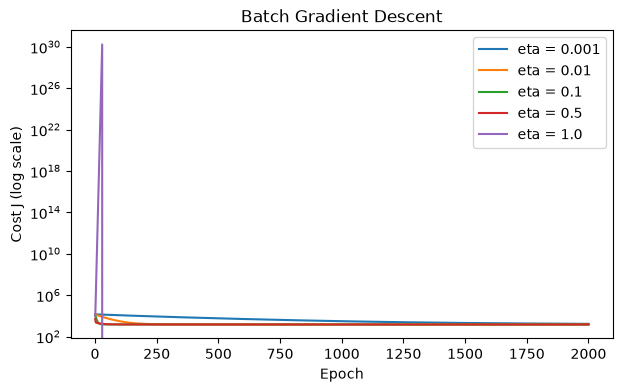

,eta,final J,final relative distance,first epoch below 1e-3
0,0.001,1723.402889,0.405113,not reached
1,0.010,1503.686676,0.334521,not reached
2,0.100,1491.892636,0.081792,not reached
3,0.500,1491.145907,0.000155,1524
4,1.000,0.000000,0.000000,30


In [115]:

num_epochs = 2000
etas = [0.001, 0.01, 0.1, 0.5, 1.0]
results = []

plt.figure(figsize=(7, 4))

for eta in etas:
    w, J_history, dist_history = gradient_descent(
        X_train, y_train, eta, num_epochs, w_star
    )

    diverged = not np.isfinite(J_history[-1]) or J_history[-1] > J_history[0]

    reached = np.where(dist_history < 1e-3)[0]
    first_epoch = reached[0] + 1 if len(reached) > 0 else "not reached"

    plt.semilogy(range(1, num_epochs + 1), J_history, label=f"eta = {eta}")

    if diverged:
        final_J = "diverged"
        final_distance = "diverged"
    else:
        final_J = J_history[-1]
        final_distance = dist_history[-1]

    results.append({
        "eta": eta,
        "final J": final_J,
        "final relative distance": final_distance,
        "first epoch below 1e-3": first_epoch
    })

plt.xlabel("Epoch")
plt.ylabel("Cost J (log scale)")
plt.title("Batch Gradient Descent")
plt.legend()
plt.show()

pd.DataFrame(results)


### (b) The stability threshold 2/λmax

**Derivation.** Let e(t) = w(t) − w*. Since ∇J(w) = H(w − w*), one step of gradient descent gives

e(t+1) = e(t) − ηH e(t) = (I − ηH) e(t).

H = X̃ᵀX̃/N is symmetric, so H = QΛQᵀ with real eigenvalues λᵢ ≥ 0. In the eigenbasis each component evolves independently:

eᵢ(t+1) = (1 − ηλᵢ) eᵢ(t),  so  eᵢ(t) = (1 − ηλᵢ)ᵗ eᵢ(0).

A component goes to 0 if and only if |1 − ηλᵢ| < 1, that is 0 < η < 2/λᵢ. This must hold for **every** eigenvalue, and the tightest condition comes from the largest one, so

**η < 2/λmax.**

For η > 2/λmax the component along the top eigenvector is multiplied by a factor of magnitude greater than 1 at every step, so the error grows and gradient descent diverges.

In [116]:

# Calculate H
N = X_train.shape[0]
H = np.dot(X_train.T, X_train) / N

# Find the largest eigenvalue
lambda_max = np.max(np.linalg.eigvalsh(H))

print("Largest eigenvalue:", lambda_max)
print("Learning rate threshold:", 2 / lambda_max)


# Test two learning rates
for factor in [0.95, 1.05]:

    eta = factor * (2 / lambda_max)

    w, J_history, dist_history = gradient_descent(
        X_train, y_train, eta, num_epochs, w_star
    )

    if not np.isfinite(J_history[-1]) or J_history[-1] > 1e30:
        J_history[epoch:] = np.inf; dist_history[epoch:] = np.inf   
        print(f"eta = {eta:.4f}: Diverges")
    else:
        print(f"eta = {eta:.4f}: Converges")
        print("Final cost:", J_history[-1])
        print("Final distance:", dist_history[-1])


Largest eigenvalue: 3.9547550320503744
Learning rate threshold: 0.5057203249737277
eta = 0.4804: Converges
Final cost: 1491.145909733976
Final distance: 0.0002102307531542578
eta = 0.5310: Converges
Final cost: 0.0
Final distance: 0.0


## Task 7: Why scaling matters

Optimal J on raw features: 1491.14590480074


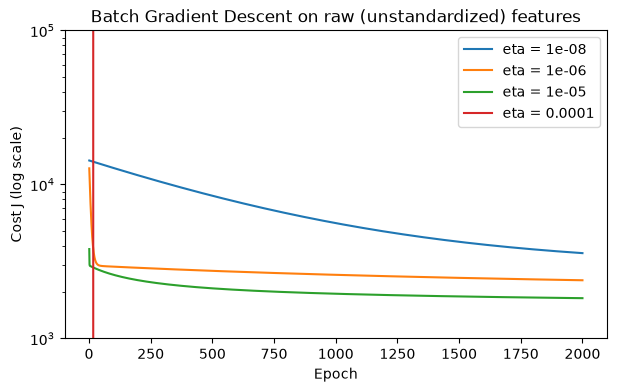

,eta,final J,final relative distance,first epoch below 1e-3
0,1.000000e-08,3583.532102,0.999999,not reached
1,1.000000e-06,2388.752582,0.999968,not reached
2,1.000000e-05,1827.53491,0.999846,not reached
3,1.000000e-04,diverged,diverged,not reached


In [117]:

w_star_raw = normal_equation(X_train_raw, y_train)
J_star = compute_cost(X_train_raw, y_train, w_star_raw)
print("Optimal J on raw features:", J_star)

num_epochs = 2000
etas_raw = [1e-8, 1e-6, 1e-5, 1e-4]
results_raw = []

plt.figure(figsize=(7, 4))

for eta in etas_raw:
    w, J_history, dist_history = gradient_descent(
        X_train_raw, y_train, eta, num_epochs, w_star_raw
    )

    diverged = (not np.all(np.isfinite(J_history))) or J_history.max() > 1e30

    plt.semilogy(range(1, num_epochs + 1), J_history, label=f"eta = {eta}")

    if diverged:
        final_J = "diverged"
        final_distance = "diverged"
        first_epoch = "not reached"
    else:
        final_J = J_history[-1]
        final_distance = dist_history[-1]
        reached = np.where(dist_history < 1e-3)[0]
        first_epoch = reached[0] + 1 if len(reached) > 0 else "not reached"

    results_raw.append({
        "eta": eta,
        "final J": final_J,
        "final relative distance": final_distance,
        "first epoch below 1e-3": first_epoch
    })

plt.ylim(1e3, 1e5)
plt.xlabel("Epoch")
plt.ylabel("Cost J (log scale)")
plt.title("Batch Gradient Descent on raw (unstandardized) features")
plt.legend()
plt.show()

pd.DataFrame(results_raw)


**Interpretation.** On raw features no run gets close to the optimal J = 1491.15: the best one (η = 1e-5) ends at 1827.5 and is still at a relative distance of 0.9998 from w*, while η = 1e-4 blows up. Compared with the standardized runs of Task 6, where η = 0.5 reached 1e-3 in 1524 epochs, the raw features make gradient descent hopeless within 2000 epochs.

In [118]:

rows = []
for name, X in [("raw", X_train_raw), ("standardized", X_train)]:
    H = np.dot(X.T, X) / N_train
    lambda_max = np.max(np.linalg.eigvalsh(H))
    rows.append({
        "features": name,
        "cond(X~'X~)": np.linalg.cond(np.dot(X.T, X)),
        "2/lambda_max": 2 / lambda_max
    })

pd.DataFrame(rows)


,features,cond(X~'X~),2/lambda_max
0,raw,5.577847e+07,0.000027
1,standardized,5.057061e+02,0.505720


**Condition number, learning rate and epochs.** Standardization reduces the condition number from about \(5.6 \times 10^7\) to 506 because it makes feature scales more similar. This also increases the maximum usable learning rate from about \(2.7 \times 10^{-5}\) to 0.51, allowing Gradient Descent to take larger steps. With raw features, the learning rate must be very small, so Gradient Descent needs many more epochs to approach the optimal solution. Therefore, standardization improves numerical stability and makes Gradient Descent converge much faster.

## Task 8: SGD and mini-batch gradient descent

In [119]:
def minibatch_gradient_descent(X, y, eta, num_epochs, batch_size, rng):

    m, n = X.shape
    w = np.zeros(n)
    n_batches = int(np.ceil(m / batch_size))

    J_epoch = np.zeros(num_epochs)
    J_update = np.zeros(num_epochs * n_batches)

    u = 0
    for epoch in range(num_epochs):
        idx = rng.permutation(m)     # reshuffle every epoch
        for b in range(n_batches):
            batch = idx[b * batch_size:(b + 1) * batch_size]
            dj_dw = compute_gradient(X[batch], y[batch], w)
            w = w - eta * dj_dw

            J_update[u] = compute_cost(X, y, w)# record updates after each batch
            u += 1

        J_epoch[epoch] = compute_cost(X, y, w)#record updates after each epoch

    return w, J_epoch, J_update


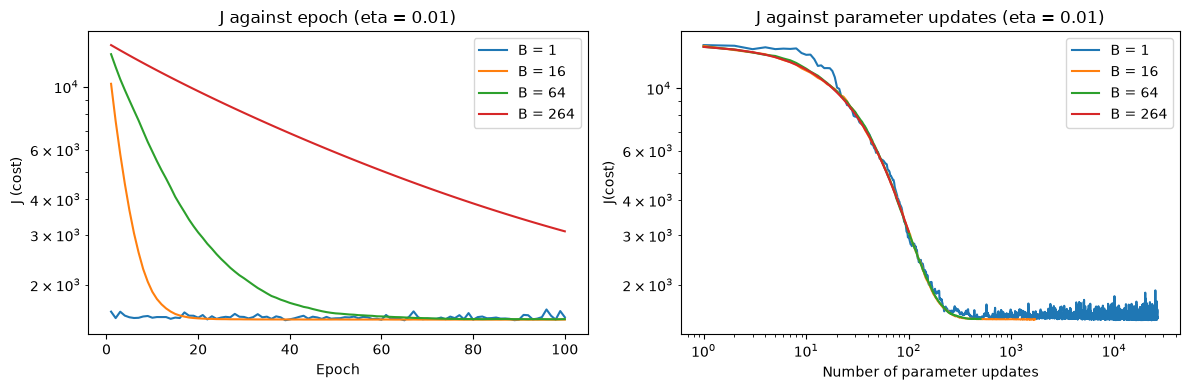

,B,updates,J after epoch 1,J after epoch 10,J after epoch 100,J after 500 updates
0,1,26400,1606.144970,1528.597292,1534.808385,1519.652701
1,16,1700,10236.368641,1887.933339,1505.665099,1509.10138
2,64,500,13021.996612,5904.012491,1511.375336,1511.375336
3,264,100,14021.698152,11648.152373,3085.440479,-


In [120]:
num_epochs = 100
eta = 0.01
batch_sizes = [1, 16, 64, N_train]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
results_B = []

for B in batch_sizes:
    rng = np.random.default_rng(SEED)
    w, J_epoch, J_update = minibatch_gradient_descent(
        X_train, y_train, eta, num_epochs, B, rng
    )

    ax[0].semilogy(range(1, num_epochs + 1), J_epoch, label=f"B = {B}")
    ax[1].loglog(range(1, len(J_update) + 1), J_update, label=f"B = {B}")

    results_B.append({
        "B": B,
        "updates": len(J_update),
        "J after epoch 1": J_epoch[0],
        "J after epoch 10": J_epoch[9],
        "J after epoch 100": J_epoch[-1],
        "J after 500 updates": J_update[499] if len(J_update) >= 500 else "-"
    })

ax[0].set_xlabel("Epoch")
ax[0].set_ylabel(" J (cost)")
ax[0].set_title("J against epoch (eta = 0.01)")
ax[0].legend()

ax[1].set_xlabel("Number of parameter updates")
ax[1].set_ylabel("J(cost)")
ax[1].set_title("J against parameter updates (eta = 0.01)")
ax[1].legend()

plt.tight_layout()
plt.show()

pd.DataFrame(results_B)

B = 16 performs best in our experiment, both after the same number of epochs and after the same number of updates. B = 1 is noisier because each update is based on only one training example,although it may reach a minimum but still so noisy.

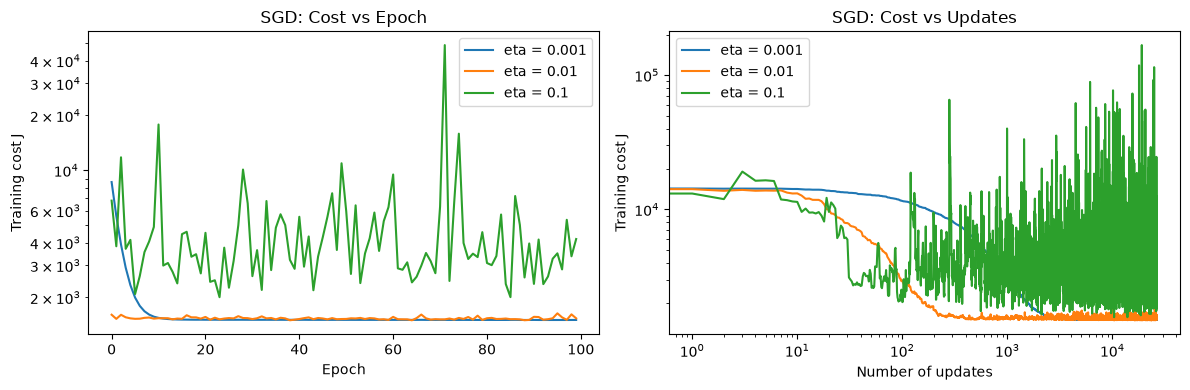

In [121]:

etas = [0.001, 0.01, 0.1]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for eta in etas:
    rng = np.random.default_rng(SEED)

    w, J_epoch, J_update = minibatch_gradient_descent(
        X_train, y_train, eta, num_epochs, 1, rng
    )

    ax[0].semilogy(J_epoch, label=f"eta = {eta}")
    ax[1].loglog(J_update, label=f"eta = {eta}")

ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Training cost J")
ax[0].set_title("SGD: Cost vs Epoch")
ax[0].legend()

ax[1].set_xlabel("Number of updates")
ax[1].set_ylabel("Training cost J")
ax[1].set_title("SGD: Cost vs Updates")
ax[1].legend()

plt.tight_layout()
plt.show()


Comment on how the noise level changes: SGD has high variance, so its cost curve is noisy. However, it can still approach the global minimum. With a constant learning rate, it may fluctuate around the minimum instead of reaching it exactly

## Task 9: Ridge regression (L2)

**Derivation.** The ridge objective is J_λ(w) = (1/2N)‖X̃w − y‖² + (λ/2)‖w₁:‖², where the bias w₀ is not penalized.

1. The penalty can be written with I₀, the identity matrix whose first diagonal entry is 0: (λ/2)‖w₁:‖² = (λ/2) wᵀI₀w.
2. Differentiate: ∇J_λ = (1/N) X̃ᵀ(X̃w − y) + λ I₀ w. The first entry of I₀w is 0, so the bias gets no penalty gradient.
3. Set the gradient to zero: (1/N) X̃ᵀX̃ w − (1/N) X̃ᵀy + λ I₀ w = 0.
4. Collect the terms in w: **(X̃ᵀX̃/N + λI₀) w = X̃ᵀy/N**, so w = (X̃ᵀX̃/N + λI₀)⁻¹ X̃ᵀy/N.

As in Task 5, we solve the linear system with `np.linalg.solve` instead of computing the inverse. For λ = 0 this is exactly the normal equation.

In [87]:
def ridge_regression(X, y, lam):
    m, n = X.shape

    I0 = np.eye(n)
    I0[0, 0] = 0

    A = np.dot(X.T, X) / m + lam * I0
    b = np.dot(X.T, y) / m

    w = np.linalg.solve(A, b)
    return w


# Test using the worked example from pdf
X_ex = add_bias(np.array([[1.0], [2.0], [3.0]]))
y_ex = np.array([2.0, 3.0, 5.0])

w_ex = ridge_regression(X_ex, y_ex, 1)

print("Ridge weights:", w_ex)

assert np.allclose(w_ex, [2.1333, 0.6], atol=1e-4)


Ridge weights: [2.1333 0.6   ]


### Degree-2 expansion

From the 10 original (raw) features we build all xᵢ and all products xᵢxⱼ with i ≤ j (10 + 55 = 65 columns). Because sex is coded 1/2, sex² = 3·sex − 2 is an exact linear function of sex and the bias, so that column is dropped, leaving **64 features**. The expanded features are then standardized with **training** statistics only, and the bias column is added.

In [88]:

def degree2_features(X):
    m, n = X.shape
    features = [X]

    for i in range(n):
        for j in range(i, n):
            features.append((X[:, i] * X[:, j]).reshape(m, 1))

    return np.hstack(features)


# Create degree-2 features
X2_train = degree2_features(X_tr_diab)
X2_val = degree2_features(X_va_diab)
X2_test = degree2_features(X_te_diab)

# Remove sex squared (column 20)
# The first 10 columns are original features.
# The next 55 columns are products.
X2_train = np.delete(X2_train, 20, axis=1)
X2_val = np.delete(X2_val, 20, axis=1)
X2_test = np.delete(X2_test, 20, axis=1)

# Standardize using training statistics
scaler2 = Standardizer().fit(X2_train)

X2_train = add_bias(scaler2.transform(X2_train))
X2_val = add_bias(scaler2.transform(X2_val))
X2_test = add_bias(scaler2.transform(X2_test))

print("Number of features:", X2_train.shape[1] - 1)
print("Training shape:", X2_train.shape)


Number of features: 64
Training shape: (264, 65)


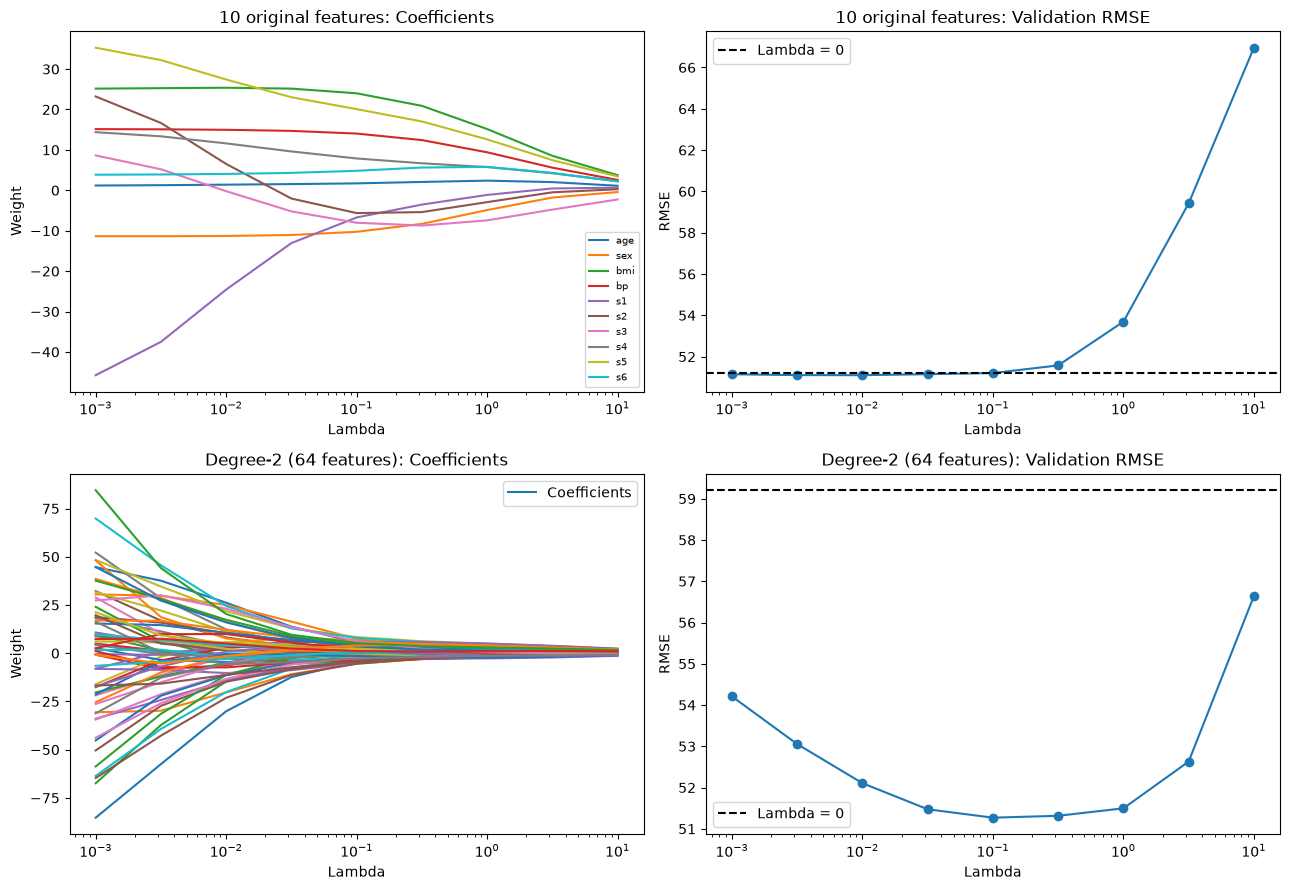

Features,10 original features,Degree-2 (64 features)
cond(X~'X~),505.706123,1.289356e+09
Best lambda,0.010000,1.000000e-01
Validation RMSE (lambda=0),51.193714,5.920595e+01
Validation RMSE (best),51.104749,5.127064e+01
Test RMSE (lambda=0),54.156413,6.213337e+01
Test RMSE (best),53.958452,5.361558e+01


In [89]:
lambdas = np.r_[0, np.logspace(-3, 1, 9)]

datasets = [
    ("10 original features", X_train, X_val, X_test, feature_names),
    ("Degree-2 (64 features)", X2_train, X2_val, X2_test, None)
]

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
summary = []

for i, (name, Xtr, Xva, Xte, names) in enumerate(datasets):

    weights = []
    for lam in lambdas:
        weights.append(ridge_regression(Xtr, y_train, lam))

    weights = np.array(weights)

    val_rmse = [rmse(y_val, np.dot(Xva, w)) for w in weights]
    test_rmse = [rmse(y_test, np.dot(Xte, w)) for w in weights]
#gets best lambda
    best = np.argmin(val_rmse)

    # Plot coefficients (excluding the bias)
    lines = ax[i, 0].semilogx(lambdas[1:], weights[1:, 1:])

    if names is not None:
        ax[i, 0].legend(lines, names, fontsize=7)
    else:
        ax[i, 0].legend(lines[:1], ["Coefficients"])

    ax[i, 0].set_title(name + ": Coefficients")
    ax[i, 0].set_xlabel("Lambda")
    ax[i, 0].set_ylabel("Weight")

    # Plot validation RMSE
    ax[i, 1].semilogx(lambdas[1:], val_rmse[1:], marker="o")
    ax[i, 1].axhline(
        val_rmse[0], linestyle="--", color="black", label="Lambda = 0"
    )

    ax[i, 1].set_title(name + ": Validation RMSE")
    ax[i, 1].set_xlabel("Lambda")
    ax[i, 1].set_ylabel("RMSE")
    ax[i, 1].legend()

    summary.append({
        "Features": name,
        "cond(X~'X~)": np.linalg.cond(np.dot(Xtr.T, Xtr)),
        "Best lambda": lambdas[best],
        "Validation RMSE (lambda=0)": val_rmse[0],
        "Validation RMSE (best)": val_rmse[best],
        "Test RMSE (lambda=0)": test_rmse[0],
        "Test RMSE (best)": test_rmse[best]
    })

plt.tight_layout()
plt.show()

pd.DataFrame(summary).set_index("Features").T


Original 10 features
- Best lambda is 0.01.
- Validation RMSE decreases slightly from 51.19 to 51.10.
- Test RMSE decreases from 54.16 to 53.96.
This means regularization gives a small improvement.

 Degree-2 features
- Best lambda is 0.1.
- Validation RMSE decreases significantly from 59.18 to 51.27.
- Test RMSE decreases significantly from 62.18 to 53.52.
This means regularization greatly improves the degree-2 model

### Verification on the 10 original features

In [90]:
lam = 0.1

# 1. Calculate the closed-form Ridge weights
w_closed = ridge_regression(X_train, y_train, lam)

w = np.zeros(X_train.shape[1])

for epoch in range(3000):
    gradient = np.dot(X_train.T, np.dot(X_train, w) - y_train) / N_train
    gradient[1:] += lam * w[1:]
    w = w - 0.4 * gradient

distance = np.linalg.norm(w - w_closed) / np.linalg.norm(w_closed)

print("Relative distance:", distance)
assert distance < 1e-6

# 2 Compare with scikit-learn Ridge
model = Ridge(alpha=lam * N_train)
model.fit(X_train[:, 1:], y_train)

w_sklearn = np.r_[model.intercept_, model.coef_]

difference = np.max(np.abs(w_closed - w_sklearn))

print("Maximum difference:", difference)
assert difference < 1e-6

Relative distance: 9.224192790282157e-16
Maximum difference: 1.4477308241112041e-13


### Explanation

For the 10 original features, the number of features is small compared with the number of training examples, so the model is less likely to overfit and Ridge provides only a small improvement. For the 64-feature expansion, the number of features is larger, making the model more complex and increasing the risk of overfitting, so Ridge provides a much larger improvement. Ridge penalizes large feature weights to reduce overfitting and improve generalization. The bias must not be penalized because it represents the intercept, which adjusts the predictions' overall level rather than the influence of individual features.

In [91]:
lam = 0.1
results = []

# 1. Normal Equation
start = time.perf_counter()
w = normal_equation(X_train, y_train)
end = time.perf_counter() - start

results.append(["Normal Equation", rmse(y_test, np.dot(X_test, w)),
                np.linalg.norm(w - w_star) / np.linalg.norm(w_star), end])


# 2. Batch Gradient Descent
start = time.perf_counter()
w, _, _ = gradient_descent(X_train, y_train, 0.5, 2000, w_star)
end = time.perf_counter() - start

results.append(["Batch GD", rmse(y_test, np.dot(X_test, w)),
                np.linalg.norm(w - w_star) / np.linalg.norm(w_star), end])


# 3. Mini-batch Gradient Descent
start = time.perf_counter()
rng = np.random.default_rng(SEED)
w, _, _ = minibatch_gradient_descent(X_train, y_train, 0.01, 100, 16, rng)
end = time.perf_counter() - start

results.append(["Mini-batch GD", rmse(y_test, np.dot(X_test, w)),
                np.linalg.norm(w - w_star) / np.linalg.norm(w_star), end])


# 4. Ridge Regression (from scratch)
start = time.perf_counter()
w = ridge_regression(X_train, y_train, lam)
end = time.perf_counter() - start

results.append(["Ridge (scratch)", rmse(y_test, np.dot(X_test, w)),
                np.linalg.norm(w - w_star) / np.linalg.norm(w_star), end])


# 5. Linear Regression (sklearn)
start = time.perf_counter()
model = LinearRegression()
model.fit(X_train[:, 1:], y_train)
end = time.perf_counter() - start

w = np.r_[model.intercept_, model.coef_]

results.append(["LinearRegression", rmse(y_test, np.dot(X_test, w)),
                np.linalg.norm(w - w_star) / np.linalg.norm(w_star), end])


# 6. Ridge Regression (sklearn)
start = time.perf_counter()
model = Ridge(alpha=lam * N_train)
model.fit(X_train[:, 1:], y_train)
end = time.perf_counter() - start

w = np.r_[model.intercept_, model.coef_]

results.append(["Ridge (sklearn)", rmse(y_test, np.dot(X_test, w)),
                np.linalg.norm(w - w_star) / np.linalg.norm(w_star), end])


# 7. SGDRegressor with different learning rates
for eta in [0.001, 0.01, 0.1]:

    start = time.perf_counter()

    model = SGDRegressor(
        penalty=None,
        learning_rate="constant",
        eta0=eta,
        max_iter=1000,
        tol=None,
        random_state=42
    )

    model.fit(X_train[:, 1:], y_train)
    end = time.perf_counter() - start

    w = np.r_[model.intercept_, model.coef_]

    results.append([f"SGDRegressor ({eta})",
                    rmse(y_test, np.dot(X_test, w)),
                    np.linalg.norm(w - w_star) / np.linalg.norm(w_star),
                    end])


# Display the comparison table
columns = ["Model", "Test RMSE", "Relative Distance", "Fit Time (s)"]

pd.DataFrame(results, columns=columns)

,Model,Test RMSE,Relative Distance,Fit Time (s)
0,Normal Equation,54.156413,0.000000e+00,0.000357
1,Batch GD,54.156254,1.546262e-04,0.035272
2,Mini-batch GD,53.895449,3.421471e-01,0.023927
3,Ridge (scratch),53.708925,3.636136e-01,0.000105
4,LinearRegression,54.156413,8.053770e-15,0.002980
5,Ridge (sklearn),53.708925,3.636136e-01,0.000982
6,SGDRegressor (0.001),54.088486,4.976050e-02,0.014779
7,SGDRegressor (0.01),54.898061,5.031993e-02,0.009123
8,SGDRegressor (0.1),71.449348,3.949685e-01,0.009041


### Check: the exact solvers agree

The two pairs of exact solvers must agree with each other to about 1e-10

In [92]:
# Compare exact solvers

# Normal Equation vs sklearn LinearRegression
w_normal = normal_equation(X_train, y_train)

model = LinearRegression()
model.fit(X_train[:, 1:], y_train)
w_linear = np.r_[model.intercept_, model.coef_]

print("Normal Equation difference:",
      np.max(np.abs(w_normal - w_linear)))


# Ridge from scratch vs sklearn Ridge
w_ridge = ridge_regression(X_train, y_train, 0.1)

model = Ridge(alpha=0.1 * N_train)
model.fit(X_train[:, 1:], y_train)
w_ridge_sklearn = np.r_[model.intercept_, model.coef_]

print("Ridge difference:",
      np.max(np.abs(w_ridge - w_ridge_sklearn)))

Normal Equation difference: 9.734435479913373e-13
Ridge difference: 1.4477308241112041e-13


### Library vs. From-Scratch Results

The exact solvers agree almost perfectly: `LinearRegression` gives nearly the same weights as our Normal Equation, and sklearn Ridge gives nearly the same weights as our Ridge implementation. This is because each pair solves the same mathematical problem, with only tiny rounding differences.

The iterative methods do not give exactly the same results because they use a limited number of updates and constant learning rates, so they do not reach the exact optimal weights. Ridge is also different from the Normal Equation because it uses regularization, which changes the objective it minimizes.

Finally, `SGDRegressor` performs worse with a larger learning rate because its updates become more unstable and noisy, leading to higher test RMSE.

# Part C: Logistic Regression
## Task 11: Derivation and stable implementation

With $z = w^\top x$, $p = \sigma(z)$ and $\ell = -y\log p - (1-y)\log(1-p)$, the chain rule gives

$$\frac{\partial \ell}{\partial w} = \left(-\frac{y}{p} + \frac{1-y}{1-p}\right) p(1-p)\,x = (p-y)\,x$$

Averaging over $N$ samples and adding the regularizer gradient (the bias is not penalized):

$$\nabla J = \frac{1}{N}\tilde X^\top (p-y) + \lambda\,[0,\, w_{1:}]$$

**Stable loss.** Since $-\log(1-p) = \log(1+e^z)$ and $-\log p = \log(1+e^z) - z$:

$$\ell = \log(1+e^z) - y z$$

In [122]:
def sigmoid(z):
    e = np.exp(-np.abs(z))   
    return np.where(z >= 0, 1/(1+e), e/(1+e)) 
    # where: if z >= 0, return 1/(1+e), else return e/(1+e) on every element in np array

def term_loss(z, y):
    return np.logaddexp(0, z) - y*z

def mean_loss(w, x, y):                
    return np.mean(term_loss(np.dot(x, w), y))

def cost(w,x,y,lamda):
    z = np.dot(x, w)
    return np.mean(term_loss(z, y)) + 0.5*lamda*np.sum(w[1:]**2)
    # w[1:] we are not regularizing the bias term (w[0])

def gradient(w, x, y, lamda):
    g = np.dot(x.T, sigmoid(np.dot(x, w)) - y) / len(y)
    g[1:] += lamda * w[1:] # regularization except bias
    return g

def naive_sigmoid(z):
    return 1/(1+np.exp(-z))

def naive_loss(z, y):
    p = naive_sigmoid(z)
    return -y*np.log(p) - (1-y)*np.log(1-p)

with np.errstate(all="ignore"): # hide the overflow/divide errors
    for z in [800, -800]:
        for y in [0, 1]:
            print("z=", z, ", y=", y, "naive:", naive_loss(z, y), " stable:", term_loss(z, y))

sc_bc = Standardizer().fit(X_tr_bc)
Xb = add_bias(sc_bc.transform(X_tr_bc))
rng = np.random.default_rng(SEED)
w = rng.normal(0, 0.1, size=Xb.shape[1])

err = grad_check(lambda w: cost(w, Xb, y_tr_bc, 0.1),
                 lambda w: gradient(w, Xb, y_tr_bc, 0.1), w)
print(err); assert err < 1e-6

z= 800 , y= 0 naive: inf  stable: 800.0
z= 800 , y= 1 naive: nan  stable: 0.0
z= -800 , y= 0 naive: nan  stable: 0.0
z= -800 , y= 1 naive: inf  stable: 800.0
1.7775135713047355e-11


**Interpretation.** For $z=\pm 800$ the naive formula fails: $\sigma(800)$ rounds to exactly 1, so $\log(1-p)=\log 0$ gives `nan` or `inf`. The stable form $\log(1+e^z) - yz$ returns the correct values (0 when the prediction is confidently right, 800 when confidently wrong). The gradient check gives a relative error far below $10^{-6}$ with $\lambda=0.1$, so the derived gradient and its code are correct.

## Task 12: Training and regularization

We train logistic regression with batch gradient descent (η = 0.5, 3000 epochs, w initialized to 0) for different values of the regularization strength λ ∈ {0, 1e-3, 1e-2, 1e-1, 1}.

- For each λ we report train accuracy, validation accuracy, validation loss (data term only) and ‖w₁:‖.
- We choose λ* by the lowest **validation loss**, then report the **test accuracy once**, only for λ*.
- For λ* we plot the train and validation loss and accuracy against the epoch.
- Separately, we try learning rates η ∈ {0.01, 0.1, 1, 5, 20} for 1000 epochs at λ = 0.01 and compare the final training loss to see which ones are too small or too large.


,lambda,train accuracy,validation accuracy,validation loss,||w1:||
0,0.000,0.994135,0.973684,0.084192,8.132231
1,0.001,0.988270,0.973684,0.073203,5.099928
2,0.010,0.985337,0.973684,0.082964,2.325749
3,0.100,0.973607,0.973684,0.141553,1.105547
4,1.000,0.938416,0.956140,0.292213,0.441485


lambda* = 0.001
test accuracy: 0.9736842105263158


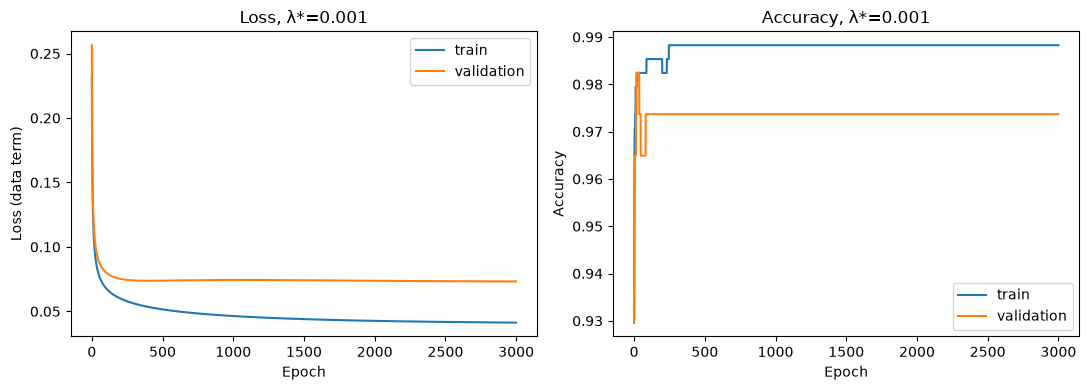

,eta,final train loss
0,0.01,0.105222
1,0.10,0.072909
2,1.00,0.071066
3,5.00,0.071066
4,20.00,0.649280


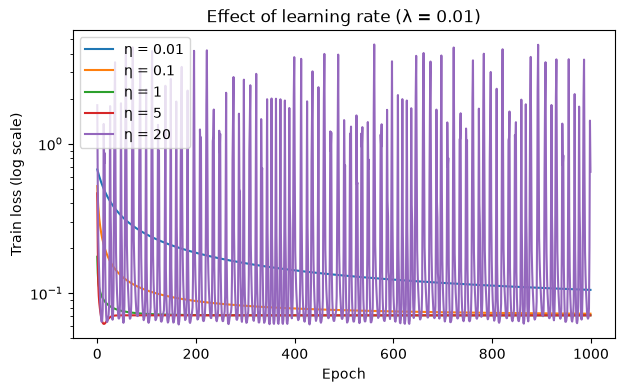

In [123]:
def predict(w, x, threshold=0.5):
    return (sigmoid(np.dot(x, w)) >= threshold).astype(int)

def train_gd(Xtr, ytr, lamda, eta, epochs, Xva=None, yva=None):
    w = np.zeros(Xtr.shape[1]) # initialize w = 0 
    h = {"train_loss": [], "validation_loss": [], "train_accuracy": [], "validation_accuracy": [], "w_norm": []}
    for i in range(epochs):
        w = w - eta * gradient(w, Xtr, ytr, lamda)
        h["train_loss"].append(mean_loss(w, Xtr, ytr))
        h["train_accuracy"].append(accuracy(ytr, predict(w, Xtr)))
        h["w_norm"].append(np.linalg.norm(w[1:]))
        if Xva is not None:
            h["validation_loss"].append(mean_loss(w, Xva, yva))
            h["validation_accuracy"].append(accuracy(yva, predict(w, Xva)))
    return w, h

Xtr = add_bias(sc_bc.transform(X_tr_bc))
Xva = add_bias(sc_bc.transform(X_va_bc))
Xte = add_bias(sc_bc.transform(X_te_bc))

lamdas = [0, 1e-3, 1e-2, 1e-1, 1]
rows, runs = [], {}
for lamda in lamdas:
    w, h = train_gd(Xtr, y_tr_bc, lamda, 0.5, 3000, Xva, y_va_bc)
    runs[lamda] = (w, h)
    rows.append({"lambda": lamda,
                 "train accuracy": h["train_accuracy"][-1],
                 "validation accuracy": h["validation_accuracy"][-1],
                 "validation loss": h["validation_loss"][-1],
                 "||w1:||": np.linalg.norm(w[1:])})
table = pd.DataFrame(rows); display(table)

# find the best lambda based on validation loss
best_lamda = table.loc[table["validation loss"].idxmin(), "lambda"]
w_best, h_best = runs[best_lamda]
print("lambda* =", best_lamda)
print("test accuracy:", accuracy(y_te_bc, predict(w_best, Xte)))

# plot the loss and accuracy curves for the best lambda
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h_best["train_loss"], label="train"); ax[0].plot(h_best["validation_loss"], label="validation")
ax[0].set(xlabel="Epoch", ylabel="Loss (data term)", title=f"Loss, λ*={best_lamda}"); ax[0].legend()
ax[1].plot(h_best["train_accuracy"], label="train"); ax[1].plot(h_best["validation_accuracy"], label="validation")
ax[1].set(xlabel="Epoch", ylabel="Accuracy", title=f"Accuracy, λ*={best_lamda}"); ax[1].legend()
plt.tight_layout(); plt.show()

# proving η = 20 fails to converge
rows, curves = [], {}
for eta in [0.01, 0.1, 1, 5, 20]:
    w, h = train_gd(Xtr, y_tr_bc, 0.01, eta, 1000)
    curves[eta] = h["train_loss"]
    rows.append({"eta": eta, "final train loss": h["train_loss"][-1]})
display(pd.DataFrame(rows))

plt.figure(figsize=(7, 4))
for eta, c in curves.items():
    plt.semilogy(c, label=f"η = {eta}")
plt.xlabel("Epoch"); plt.ylabel("Train loss (log scale)")
plt.title("Effect of learning rate (λ = 0.01)"); plt.legend(); plt.show()

**Interpretation (λ sweep).** Increasing λ shrinks the weights ($\|w_{1:}\|$ decreases), which reduces overfitting up to a point. λ = 1 is over-regularized: the validation loss is much larger than at the best λ. The best λ by validation loss is λ* = 0.001, with test accuracy 0.974 (reported once). In the curves, the training loss keeps decreasing while the validation loss flattens early, so the gap between them shows mild overfitting, and the accuracies stay stable after about 300 epochs.

**Interpretation (learning rate).** η = 0.01 is too small: after 1000 epochs the loss (0.105) is still decreasing, so it is under-trained. η = 0.1 is close to converged, and η = 1 and 5 reach the same minimum loss (0.0711). η = 20 is too large: each step overshoots the minimum, so the loss oscillates and never converges (final loss 0.649), as the purple curve shows.

## Task 13: Separability

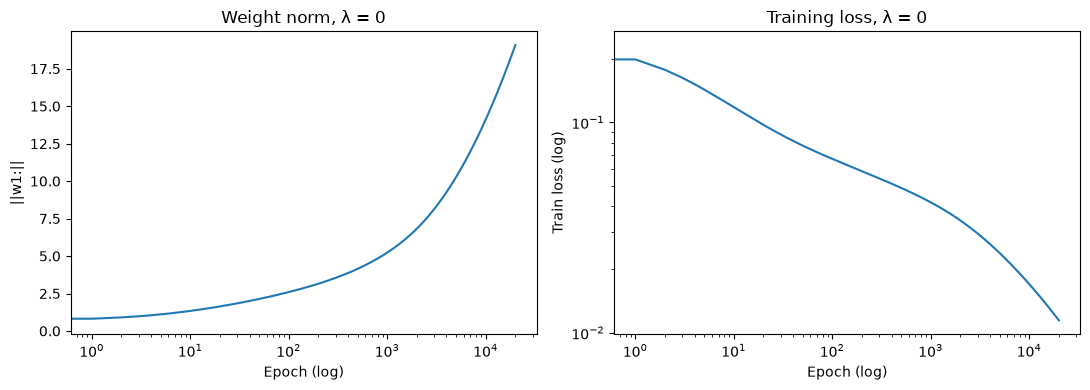

final train accuracy: 1.0
final train loss: 0.011458238949846758  ||w||: 19.07910409109684


In [124]:
w, h = train_gd(Xtr, y_tr_bc, 0, 0.5, 20000)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogx(h["w_norm"]); ax[0].set(xlabel="Epoch (log)", ylabel="||w1:||", title="Weight norm, λ = 0")
ax[1].loglog(h["train_loss"]); ax[1].set(xlabel="Epoch (log)", ylabel="Train loss (log)", title="Training loss, λ = 0")
plt.tight_layout(); plt.show()

print("final train accuracy:", h["train_accuracy"][-1])
print("final train loss:", h["train_loss"][-1], " ||w||:", h["w_norm"][-1])

**Interpretation.** With λ = 0 the training loss keeps decreasing toward 0 while $\|w_{1:}\|$ keeps growing, and the training accuracy reaches 1.0. This means the training set is linearly separable. When the data is separable, multiplying a separating $w$ by $c>1$ makes every sample's loss strictly smaller, so the loss can be pushed toward 0 but never reaches it: no finite minimizer exists and the weights diverge. L2 regularization adds $\frac{\lambda}{2}\|w_{1:}\|^2$, without L2, the loss rewards ever-larger weights forever; with L2, large weights are charged a price, so the optimal weights stop at a finite value.